In [19]:
import pandas as pd
import folium
import matplotlib.pyplot as plt
import numpy as np

In [20]:
# load the dataset and remove the top 3 rows
df = pd.read_excel("/content/ghgp_data_by_year_2023.xlsx", sheet_name = 'LDC - Direct Emissions', skiprows=3)
df

,Facility Id,FRS Id,Facility Name,State where Emissions Occur,Reported City,Reported State,Reported Zip Code,Reported Address,Reported County,Reported Latitude,...,2020 Total reported direct emissions from Local Distribution Companies,2019 Total reported direct emissions from Local Distribution Companies,2018 Total reported direct emissions from Local Distribution Companies,2017 Total reported direct emissions from Local Distribution Companies,2016 Total reported direct emissions from Local Distribution Companies,2015 Total reported direct emissions from Local Distribution Companies,2014 Total reported direct emissions from Local Distribution Companies,2013 Total reported direct emissions from Local Distribution Companies,2012 Total reported direct emissions from Local Distribution Companies,2011 Total reported direct emissions from Local Distribution Companies
0,1008026,1.100712e+11,Ameren Illinois,IL,Peoria,IL,61602,300 Liberty Street,PEORIA COUNTY,40.690450,...,74939.996,74762.846,99558.146,74961.100,73739.346,105051.594,75801.600,75662.200,75480.250,73414.440
1,1004034,1.100712e+11,Ameren Missouri,MO,St. Louis,MO,63103,1901 Chouteau Avenue,ST. LOUIS CITY,38.620667,...,14759.550,14674.950,13714.750,13668.500,13556.800,13459.200,13412.600,13353.600,13736.250,13271.750
2,1004975,1.100712e+11,Arkansas Oklahoma Gas Corp (AR),AR,Fort Smith,AR,72903,5030 South S Street,SEBASTIAN COUNTY,35.363559,...,NaN,NaN,NaN,8961.200,9771.050,11131.700,10870.500,10821.800,11025.500,11509.600
3,1006481,NaN,Arkansas Oklahoma Gas Corp (OK),OK,Fort Smith,AR,72903,5030 South S Street,NaN,35.363530,...,NaN,NaN,NaN,2983.450,2977.350,3220.500,2447.550,3111.700,3129.450,3426.500
4,1007872,1.100712e+11,Atlanta Gas Light Company,GA,Atlanta,GA,30309,Ten Peachtree Place,FULTON COUNTY,33.797114,...,165161.150,154525.296,156542.840,154795.438,151902.050,160923.894,155671.850,155513.800,191483.400,217658.900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
203,1003558,1.100712e+11,Waterville Gas & Oil Company,OH,Waterville,OH,43566,700 Farnsworth Rd.,LUCAS COUNTY,41.499160,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
204,1011115,1.100106e+11,"West Texas Gas Utility, LLC",TX,Midland,TX,79705,303 Veterans Airpark Ln. Ste 5000,MIDLAND COUNTY,31.999060,...,31068.650,31950.750,32660.800,33870.300,33632.000,35567.800,34701.350,35376.500,35376.500,35376.500
205,1002025,1.100712e+11,Wisconsin Power & Light Gas Distribution,WI,Madison,WI,53718,4902 North Biltmore Lane,DANE COUNTY,43.152170,...,21372.800,21428.400,20268.650,19805.000,19571.700,19264.200,17636.500,18285.100,18021.100,17562.298
206,1002250,1.100712e+11,Wisconsin Public Service Corporation,WI,Green Bay,WI,54307,700 North Adams,BROWN COUNTY,44.518347,...,39796.998,40010.548,38662.800,37547.798,36968.098,35729.348,35367.198,35362.198,35333.698,34779.498


In [21]:
# scout and notice there are nulls
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 26 columns):
 #   Column                                                                  Non-Null Count  Dtype  
---  ------                                                                  --------------  -----  
 0   Facility Id                                                             208 non-null    int64  
 1   FRS Id                                                                  193 non-null    float64
 2   Facility Name                                                           208 non-null    object 
 3   State where Emissions Occur                                             201 non-null    object 
 4   Reported City                                                           208 non-null    object 
 5   Reported State                                                          208 non-null    object 
 6   Reported Zip Code                                                       208 non-nu

In [22]:
# replace null values with the average of their column
df = df.fillna(df.mean(numeric_only=True))
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 26 columns):
 #   Column                                                                  Non-Null Count  Dtype  
---  ------                                                                  --------------  -----  
 0   Facility Id                                                             208 non-null    int64  
 1   FRS Id                                                                  208 non-null    float64
 2   Facility Name                                                           208 non-null    object 
 3   State where Emissions Occur                                             201 non-null    object 
 4   Reported City                                                           208 non-null    object 
 5   Reported State                                                          208 non-null    object 
 6   Reported Zip Code                                                       208 non-nu

In [23]:
# conver it to numpy array
ghg_array = df.to_numpy()
print(ghg_array)

[[1008026 110071160130.0 'Ameren Illinois' ... 75662.2 75480.25 73414.44]
 [1004034 110071160131.0 'Ameren Missouri' ... 13353.6 13736.25 13271.75]
 [1004975 110071160686.0 'Arkansas Oklahoma Gas Corp (AR)' ... 10821.8
  11025.5 11509.6]
 ...
 [1002025 110071161924.0 'Wisconsin Power & Light Gas Distribution' ...
  18285.1 18021.1 17562.298]
 [1002250 110071160885.0 'Wisconsin Public Service Corporation' ...
  35362.198 35333.698 34779.498]
 [1007107 110071161440.0 'Yankee Gas Supply' ... 76849.0 80528.65 84401.1]]


In [24]:
# emissions columns are at indices 13 through 25
emissions_only = ghg_array[:, 13:].astype(float)

# sum down columns ignoring missing values
column_sums_LDC = np.sum(emissions_only, axis=0)
print(column_sums_LDC)

[15097669.60264968 15169067.20198758 15069159.34639521 15477887.22968675
 15793386.25532121 16388006.10770731 16269222.85155556 17054300.99031579
 17108074.81419209 16975388.07160221 17918099.25454546 17517858.32148634
 17808374.54933333]


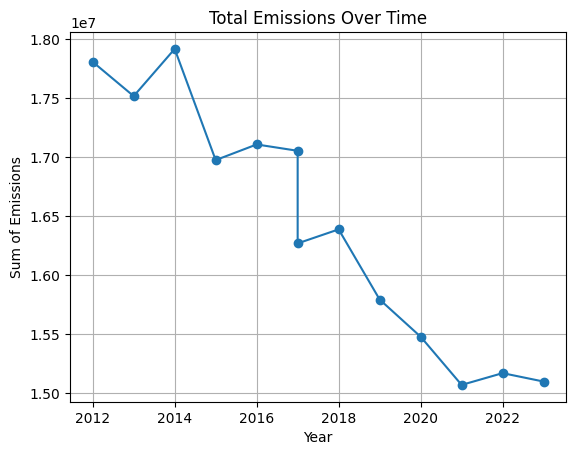

In [25]:
# plot line chart
years = np.array([2023, 2022, 2021, 2020, 2019, 2018, 2017, 2017, 2016, 2015, 2014, 2013, 2012])
plt.plot(years, column_sums_LDC, marker="o")
plt.title("Total Emissions Over Time")
plt.xlabel("Year")
plt.ylabel("Sum of Emissions")
plt.grid(True)
plt.show()


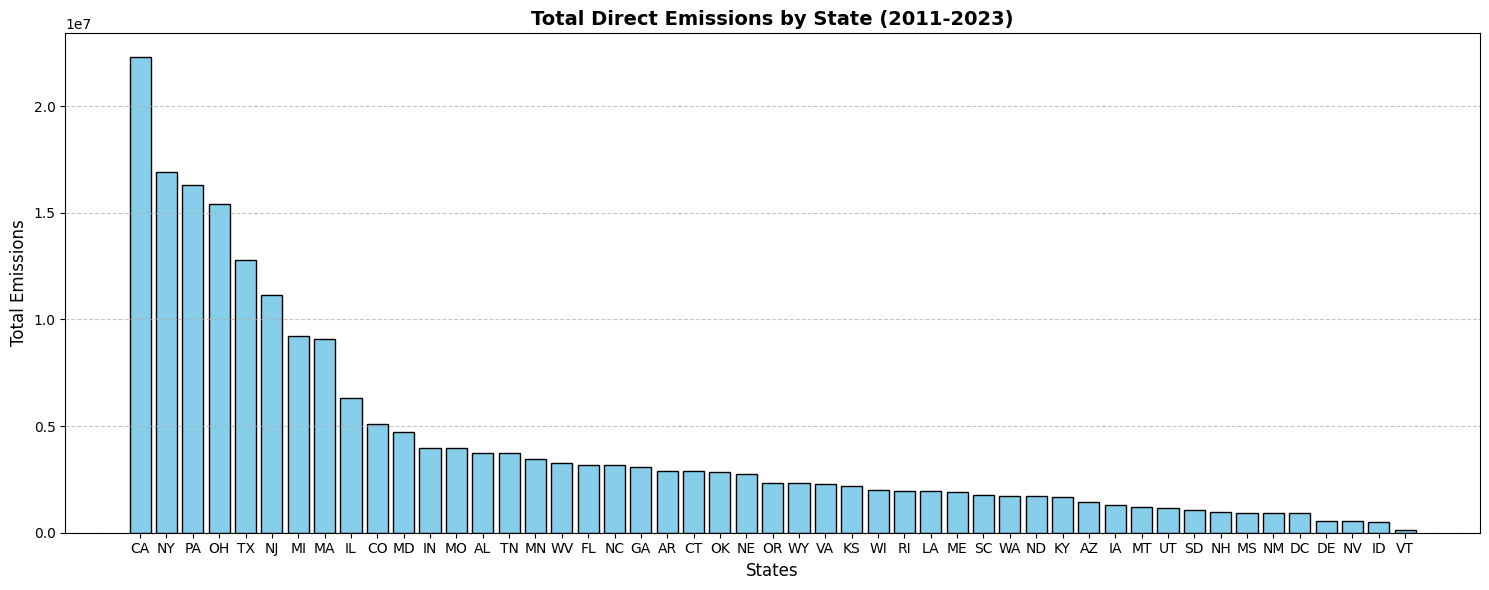

In [26]:
cols = ["2023 Total reported direct emissions from Local Distribution Companies",
 "2022 Total reported direct emissions from Local Distribution Companies",
 "2021 Total reported direct emissions from Local Distribution Companies",
 "2020 Total reported direct emissions from Local Distribution Companies",
 "2019 Total reported direct emissions from Local Distribution Companies",
 "2018 Total reported direct emissions from Local Distribution Companies",
 "2017 Total reported direct emissions from Local Distribution Companies",
 "2016 Total reported direct emissions from Local Distribution Companies",
 "2015 Total reported direct emissions from Local Distribution Companies",
 "2014 Total reported direct emissions from Local Distribution Companies",
 "2013 Total reported direct emissions from Local Distribution Companies",
 "2012 Total reported direct emissions from Local Distribution Companies",
 "2011 Total reported direct emissions from Local Distribution Companies"]

# add a new column with total emissions across all years for each facility
df["Total_Emissions_All_Years"] = df[cols].sum(axis=1)
#print(df["Total_Emissions_All_Years"])

# group by states
state_emissions = df.groupby("State where Emissions Occur")["Total_Emissions_All_Years"]

state_emissions = df.groupby("State where Emissions Occur")["Total_Emissions_All_Years"].sum()
#print(state_emissions)

state_emissions = df.groupby("State where Emissions Occur")["Total_Emissions_All_Years"].sum().reset_index()
#print(state_emissions)

# sort values
state_emissions = state_emissions.sort_values(by="Total_Emissions_All_Years", ascending=False)

# extract data to np arrays for plotting
states = state_emissions["State where Emissions Occur"]
emissions_by_state = state_emissions["Total_Emissions_All_Years"]

# create bar chart
plt.figure(figsize=(15,6))
plt.bar(states, emissions_by_state, color="skyblue", edgecolor="black")

plt.title("Total Direct Emissions by State (2011-2023)", fontsize=14, fontweight="bold")
plt.xlabel("States", fontsize=12)
plt.ylabel("Total Emissions", fontsize=12)
plt.grid(axis="y", linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [27]:
# now we will load Transimission Pipelines, we don't need the old df anymore so we can call this df
df = pd.read_excel("/content/ghgp_data_by_year_2023.xlsx", sheet_name = 'Transmission Pipelines', skiprows=3)
df

,Facility Id,FRS Id,Facility Name,State where Emissions Occur,Reported City,Reported State,Reported Zip Code,Reported Address,Reported County,Reported Latitude,...,Primary NAICS Code,Latest Reported Industry Type (subparts),2023 Total reported direct emissions from Transmission Pipelines,2022 Total reported direct emissions from Transmission Pipelines,2021 Total reported direct emissions from Transmission Pipelines,2020 Total reported direct emissions from Transmission Pipelines,2019 Total reported direct emissions from Transmission Pipelines,2018 Total reported direct emissions from Transmission Pipelines,2017 Total reported direct emissions from Transmission Pipelines,2016 Total reported direct emissions from Transmission Pipelines
0,1014613,1.100714e+11,Acadian Gas Pipeline System,Louisiana,Houston,TX,77002,1100 Louisiana Street,HARRIS COUNTY,29.757726,...,486210,W-TRANS,40678.788049,32176.604762,NaN,NaN,NaN,NaN,NaN,NaN
1,1012420,1.100712e+11,Algonquin Gas Transmission L.L.C.,Connecticut,Houston,TX,77079,915 North Eldridge Parkway,NaN,29.740130,...,486210,W-TRANS,NaN,NaN,1541.800000,1036.70,7735.400000,717.300000,10773.15,1264.25
2,1012420,1.100712e+11,Algonquin Gas Transmission L.L.C.,Massachusetts,Houston,TX,77079,915 North Eldridge Parkway,NaN,29.740130,...,486210,W-TRANS,NaN,NaN,1815.350000,337.40,3347.650000,23.000000,264.55,7515.45
3,1012420,1.100712e+11,Algonquin Gas Transmission L.L.C.,New Jersey,Houston,TX,77079,915 North Eldridge Parkway,NaN,29.740130,...,486210,W-TRANS,NaN,NaN,1294.500000,9.75,465.750000,1520.800000,19.25,NaN
4,1012420,1.100712e+11,Algonquin Gas Transmission L.L.C.,New York,Houston,TX,77079,915 North Eldridge Parkway,NaN,29.740130,...,486210,W-TRANS,NaN,NaN,612.950000,39.50,4692.150000,7092.200000,1551.05,24960.05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
235,1013273,1.100712e+11,WBI Energy Transmission Pipeline Facility,Montana,Bismarck,ND,58506,1250 West Century Avenue,BURLEIGH COUNTY,46.832690,...,486210,W-TRANS,NaN,NaN,2112.975240,2624.50,3916.493950,704.891554,NaN,NaN
236,1013273,1.100712e+11,WBI Energy Transmission Pipeline Facility,North Dakota,Bismarck,ND,58506,1250 West Century Avenue,BURLEIGH COUNTY,46.832690,...,486210,W-TRANS,NaN,NaN,3265.621728,2276.85,4419.993522,17891.074516,NaN,NaN
237,1013273,1.100712e+11,WBI Energy Transmission Pipeline Facility,South Dakota,Bismarck,ND,58506,1250 West Century Avenue,BURLEIGH COUNTY,46.832690,...,486210,W-TRANS,NaN,NaN,852.623118,3939.75,NaN,7658.525978,NaN,NaN
238,1013273,1.100712e+11,WBI Energy Transmission Pipeline Facility,Wyoming,Bismarck,ND,58506,1250 West Century Avenue,BURLEIGH COUNTY,46.832690,...,486210,W-TRANS,NaN,NaN,NaN,2407.55,1938.657154,316.345617,NaN,NaN


In [28]:
df = df.fillna(df.mean(numeric_only=True))

In [29]:
ghg_array = df.to_numpy()

emissions_only = ghg_array[:, 13:].astype(float)

column_sums = np.sum(emissions_only, axis=0)
column_sums_TP = np.flip(column_sums)

Transmission Pipeline: 32559302.446594384
Line Distribution: 213646494.5967785


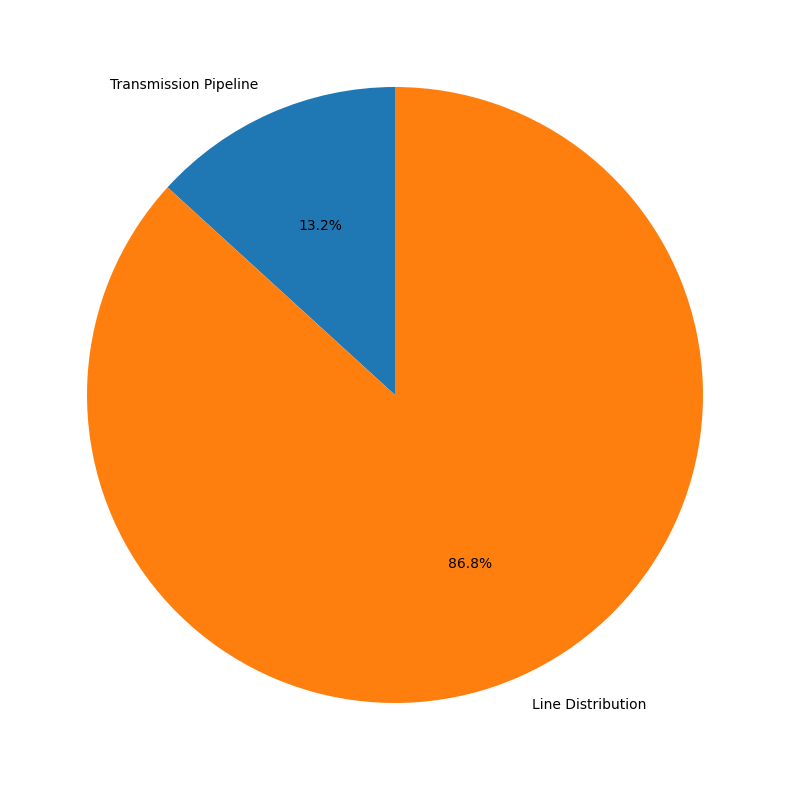

In [30]:
# pie chart

transmission_total = np.sum(column_sums_TP)
distribution_total = np.sum(column_sums_LDC)

print("Transmission Pipeline:", transmission_total)
print("Line Distribution:", distribution_total)

sector_emissions = {
    "Transmission Pipeline": transmission_total,
    "Line Distribution": distribution_total
}

plt.figure(figsize=(8,8))

plt.pie(
    sector_emissions.values(),
    labels=sector_emissions.keys(),
    autopct='%1.1f%%',
    startangle=90
)

plt.tight_layout()
plt.show()